In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [12]:
dataset = fetch_california_housing(as_frame = True)
df = dataset.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


# dataset shape

In [13]:
df.shape

(20640, 9)

# dataset describtion

In [14]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


# Select feature and target

In [15]:
X = df[["MedInc"]]
y = df["MedHouseVal"]

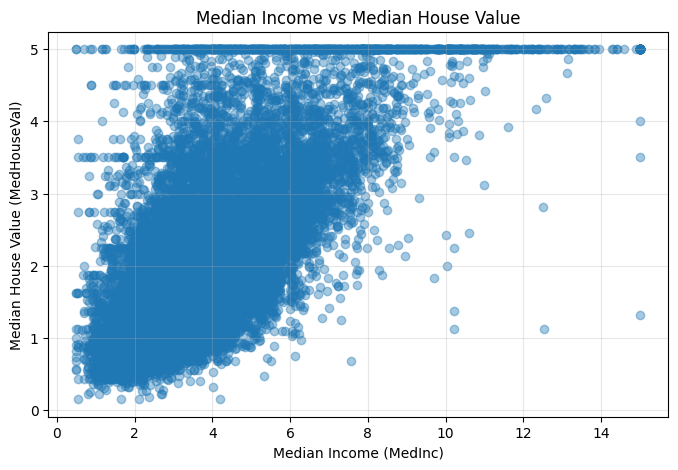

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(X["MedInc"], y, alpha=0.4)
plt.xlabel("Median Income (MedInc)")
plt.ylabel("Median House Value (MedHouseVal)")
plt.title("Median Income vs Median House Value")
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
  X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

w = model.coef_[0]
b = model.intercept_

print("\nWeight (w):", w)
print("Bias (b):", b)


Weight (w): 0.4193384939381271
Bias (b): 0.4445972916907879


In [20]:
print(
    f"For each 1-unit increase in MedInc, "
    f"the predicted MedHouseVal increases by {w:.4f} units on average."
)

For each 1-unit increase in MedInc, the predicted MedHouseVal increases by 0.4193 units on average.


In [21]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nTest Metrics:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)


Test Metrics:
MAE: 0.629908653009376
MSE: 0.7091157771765549
RMSE: 0.8420901241414455
R²: 0.45885918903846656


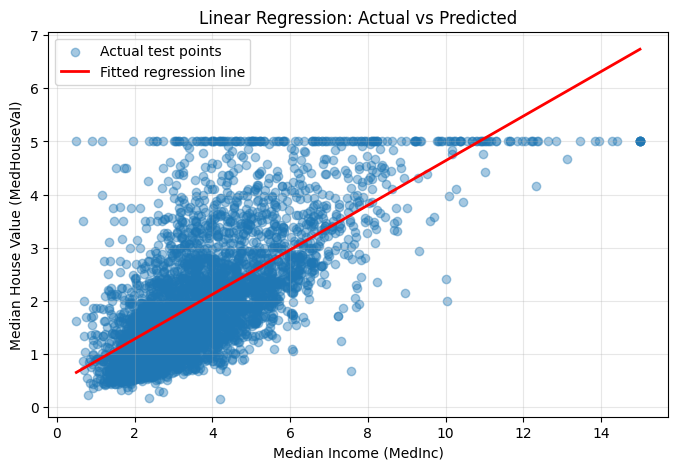

In [22]:
sorted_indices = np.argsort(X_test["MedInc"].values)
X_sorted = X_test.iloc[sorted_indices]
y_sorted_pred = y_pred[sorted_indices]

plt.figure(figsize=(8, 5))
plt.scatter(X_test["MedInc"], y_test, alpha=0.4, label="Actual test points")
plt.plot(
    X_sorted["MedInc"],
    y_sorted_pred,
    color="red",
    linewidth=2,
    label="Fitted regression line"
)

plt.xlabel("Median Income (MedInc)")
plt.ylabel("Median House Value (MedHouseVal)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
